In [1]:
%pip install -q "qiskit==2.2.3" "qiskit-optimization==0.7.0" "koreanize-matplotlib==0.1.1"

import sys
from importlib.metadata import version
print("Python:", sys.version.split()[0])
for name in ["qiskit", "qiskit-optimization", "numpy", "scipy", "torch", "matplotlib"]:
    print(name, version(name))
from qiskit.primitives import StatevectorSampler
from qiskit_optimization.minimum_eigensolvers import QAOA
from qiskit_optimization.optimizers import COBYLA
print("설치 및 import 확인 완료")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Python: 3.13.18
qiskit 2.2.3
qiskit-optimization 0.7.0
numpy 2.1.3
scipy 1.16.3
torch 2.11.0+cpu
matplotlib 3.10.0
설치 및 import 확인 완료


[EP  50] Train MSE: 0.0614 | Val MSE: 0.0591
[EP 100] Train MSE: 0.0610 | Val MSE: 0.0589
[EP 150] Train MSE: 0.0568 | Val MSE: 0.0545
[EP 200] Train MSE: 0.0555 | Val MSE: 0.0522


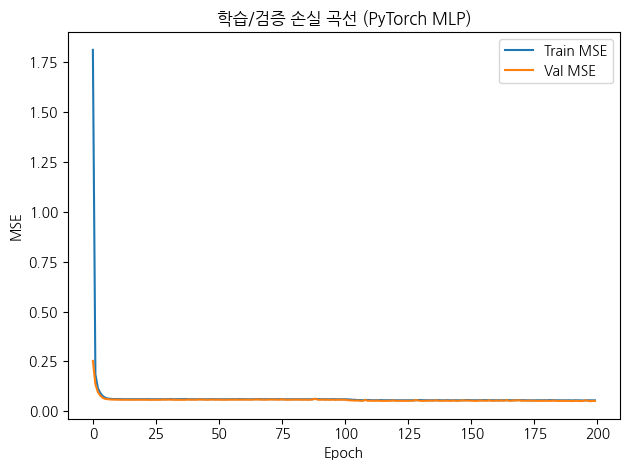

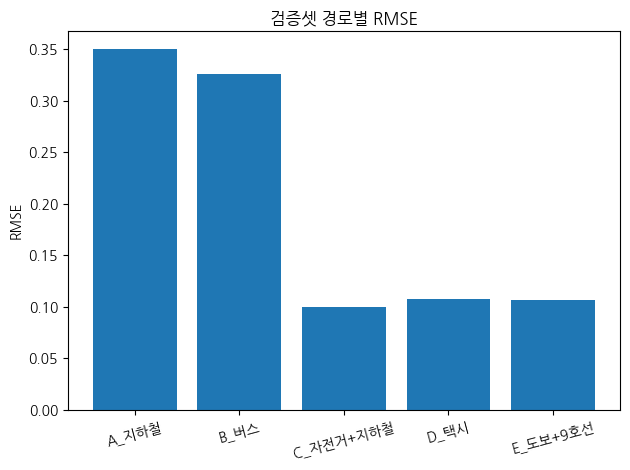


[현재 맥락] hour=8, weekday=3(목), weather=비, event=있음
 - 예측 혼잡도 A_지하철: 2.07
 - 예측 혼잡도 B_버스: 3.21
 - 예측 혼잡도 C_자전거+지하철: 1.39
 - 예측 혼잡도 D_택시: 3.02
 - 예측 혼잡도 E_도보+9호선: 1.51


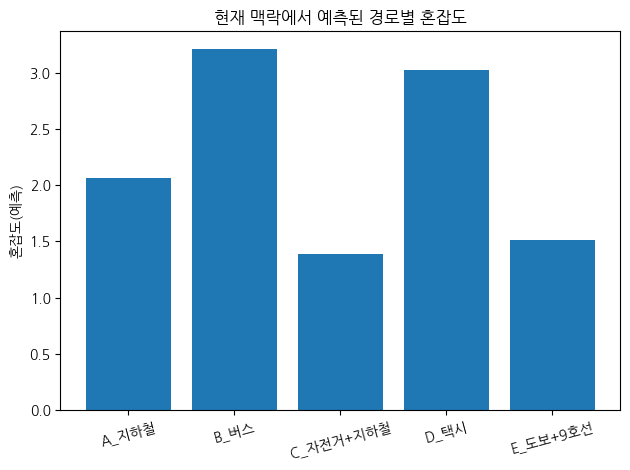

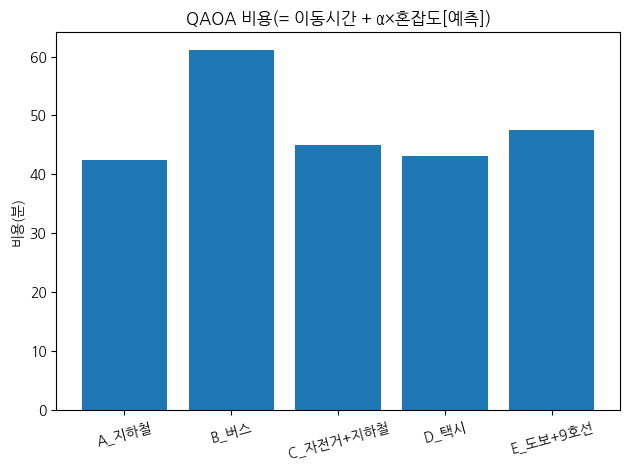

정확한 최솟값=42.343815, QAOA 후보 비용=42.343815, 차이=0.000000
유효 후보 관측 비율=0.2993, 최적 후보 관측 비율=0.2051

QAOA 하이브리드 최적 경로 결과
선택된 경로: A_지하철
예측 혼잡도: 2.07
기본 이동시간: 32 분
총 비용(= time + α×cong): 42.34
QAOA 최소비용값(fval): 42.34



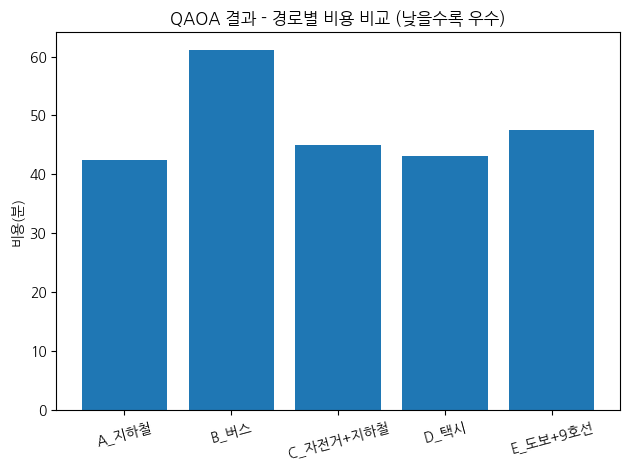

검증 MSE=0.052196, RMSE=0.228465, MAE=0.158292


In [6]:
from itertools import product
import numpy as np
from qiskit.primitives import StatevectorSampler
from qiskit_optimization.minimum_eigensolvers import QAOA
from qiskit_optimization.optimizers import COBYLA
from qiskit_optimization.algorithms import MinimumEigenOptimizer

def solve_checked(problem, reps=2, maxiter=100, seed=42):
    # 원문제의 제약을 유지한 채 내부 QUBO 변환과 역변환을 맡깁니다.
    qaoa = QAOA(
        sampler=StatevectorSampler(default_shots=4096, seed=seed),
        optimizer=COBYLA(maxiter=maxiter), reps=reps,
        initial_point=np.random.default_rng(seed).uniform(0.1, 1.0, 2*reps),
    )
    result = MinimumEigenOptimizer(qaoa).solve(problem)
    if result.x is None or not problem.is_feasible(result.x):
        raise RuntimeError("유효한 선택을 얻지 못했습니다. 샷·초깃값·탐색 예산을 바꿔 재실행하세요.")
    assert np.isclose(np.sum(result.x), 1)
    assert np.all(np.isclose(result.x, 0) | np.isclose(result.x, 1))
    assert np.isclose(result.fval, problem.objective.evaluate(result.x))
    feasible = [np.array(x) for x in product([0,1], repeat=problem.get_num_vars())
                if problem.is_feasible(np.array(x))]
    exact = min(float(problem.objective.evaluate(x)) for x in feasible)
    valid_mass = sum(float(s.probability) for s in result.samples if problem.is_feasible(s.x))
    best_mass = sum(float(s.probability) for s in result.samples
                    if problem.is_feasible(s.x) and np.isclose(s.fval, exact))
    gap = float(result.fval-exact)
    assert gap >= -1e-6 and np.isfinite(result.fval)
    assert np.isclose(sum(float(s.probability) for s in result.samples),1)
    print(f"정확한 최솟값={exact:.6f}, QAOA 후보 비용={result.fval:.6f}, 차이={gap:.6f}")
    print(f"유효 후보 관측 비율={valid_mass:.4f}, 최적 후보 관측 비율={best_mass:.4f}")
    return result

# QAOA 응용 2

import time

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

import matplotlib.pyplot as plt
import koreanize_matplotlib

from qiskit_optimization import QuadraticProgram
from qiskit_optimization.converters import QuadraticProgramToQubo

# -------------------------------------------
# 0) 기본 경로 및 설정
# -------------------------------------------
routes = ["A_지하철", "B_버스", "C_자전거+지하철", "D_택시", "E_도보+9호선"]
base_time = {
    "A_지하철": 32,
    "B_버스": 45,
    "C_자전거+지하철": 38,
    "D_택시": 28,
    "E_도보+9호선": 40,
}
alpha = 5.0

rng = np.random.default_rng(42)
torch.manual_seed(42)
torch.set_num_threads(1)

# -------------------------------------------
# 1) 합성 데이터 생성
# -------------------------------------------
def simulate_congestion(hour, weekday, weather, event):
    cong = np.array([1.5, 2.0, 1.2, 1.8, 1.3], dtype=float)
    rush = (7 <= hour <= 9) or (17 <= hour <= 19)
    if rush:
        cong[0] += 0.9
        cong[1] += 0.8
    if weather == 1:
        cong[1] += 0.7
        cong[3] += 0.7
    if event == 1:
        cong += 0.2
        cong[3] += 0.3
    if weekday in [5, 6]:
        cong[1] -= 0.2
        cong[3] -= 0.2
    cong += rng.normal(0, 0.1, size=5)
    cong = np.clip(cong, 1.0, 4.0)
    return cong

N = 2000
X = np.zeros((N, 4), dtype=float)
Y = np.zeros((N, 5), dtype=float)
for i in range(N):
    hour = rng.integers(0, 24)
    weekday = rng.integers(0, 7)
    weather = rng.integers(0, 2)
    event = rng.integers(0, 2)
    X[i] = [hour, weekday, weather, event]
    Y[i] = simulate_congestion(hour, weekday, weather, event)

Xn = X.copy()
Xn[:, 0] /= 23.0
Xn[:, 1] /= 6.0

idx = np.arange(N)
rng.shuffle(idx)
cut = int(N * 0.8)
tr_idx, va_idx = idx[:cut], idx[cut:]
Xtr, Ytr = Xn[tr_idx], Y[tr_idx]
Xva, Yva = Xn[va_idx], Y[va_idx]

# -------------------------------------------
# 2) PyTorch MLP
# -------------------------------------------
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(4, 16),
            nn.ReLU(),
            nn.Linear(16, 5),
        )
    def forward(self, x):
        return self.net(x)

device = torch.device("cpu")
model = MLP().to(device)
criterion = nn.MSELoss()
optimizer_t = torch.optim.Adam(model.parameters(), lr=0.01)

train_ds = TensorDataset(torch.tensor(Xtr, dtype=torch.float32), torch.tensor(Ytr, dtype=torch.float32))
val_ds   = TensorDataset(torch.tensor(Xva, dtype=torch.float32), torch.tensor(Yva, dtype=torch.float32))
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=256, shuffle=False)

# -------------------------------------------
# 3) 학습 루프
# -------------------------------------------
epochs = 200
tr_losses, va_losses = [], []

for ep in range(1, epochs + 1):
    model.train()
    running = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        pred = model(xb)
        loss = criterion(pred, yb)
        optimizer_t.zero_grad()
        loss.backward()
        optimizer_t.step()
        running += loss.item() * xb.size(0)
    tr_loss = running / len(train_loader.dataset)

    model.eval()
    with torch.no_grad():
        v_running = 0.0
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = model(xb)
            v_running += criterion(pred, yb).item() * xb.size(0)
        va_loss = v_running / len(val_loader.dataset)

    tr_losses.append(tr_loss)
    va_losses.append(va_loss)

    if ep % 50 == 0:
        print(f"[EP {ep:3d}] Train MSE: {tr_loss:.4f} | Val MSE: {va_loss:.4f}")

# -------------------------------------------
# 4) 손실 그래프 저장
# -------------------------------------------
plt.figure()
plt.plot(tr_losses, label="Train MSE")
plt.plot(va_losses, label="Val MSE")
plt.title("학습/검증 손실 곡선 (PyTorch MLP)")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.tight_layout()
plt.savefig("loss_curve.png")
plt.show(); plt.close()

# -------------------------------------------
# 5) 경로별 RMSE 저장
# -------------------------------------------
model.eval()
with torch.no_grad():
    xv = torch.tensor(Xva, dtype=torch.float32, device=device)
    yv = torch.tensor(Yva, dtype=torch.float32, device=device)
    pv = model(xv).cpu().numpy()
    yv_np = yv.cpu().numpy()

rmse_per_route = np.sqrt(((pv - yv_np) ** 2).mean(axis=0))
plt.figure()
plt.bar(np.arange(5), rmse_per_route)
plt.xticks(np.arange(5), routes, rotation=15)
plt.title("검증셋 경로별 RMSE")
plt.ylabel("RMSE")
plt.tight_layout()
plt.savefig("rmse_per_route.png")
plt.show(); plt.close()

# -------------------------------------------
# 6) 현재 맥락 혼잡도 예측
# -------------------------------------------
current_raw = np.array([[8, 3, 1, 1]], dtype=float)
current = current_raw.copy()
current[:, 0] /= 23.0
current[:, 1] /= 6.0

model.eval()
with torch.no_grad():
    cong_pred = model(torch.tensor(current, dtype=torch.float32, device=device)).cpu().numpy().flatten()
cong_pred = np.clip(cong_pred, 1.0, 4.0)

print("\n[현재 맥락] hour=8, weekday=3(목), weather=비, event=있음")
for r, c in zip(routes, cong_pred):
    print(f" - 예측 혼잡도 {r}: {c:.2f}")

plt.figure()
plt.bar(np.arange(5), cong_pred)
plt.xticks(np.arange(5), routes, rotation=15)
plt.title("현재 맥락에서 예측된 경로별 혼잡도")
plt.ylabel("혼잡도(예측)")
plt.tight_layout()
plt.savefig("predicted_congestion.png")
plt.show(); plt.close()

# -------------------------------------------
# 7) QAOA 비용 그래프 저장
# -------------------------------------------
costs = {r: base_time[r] + alpha * cong for r, cong in zip(routes, cong_pred)}
plt.figure()
plt.bar(np.arange(5), [costs[r] for r in routes])
plt.xticks(np.arange(5), routes, rotation=15)
plt.title("QAOA 비용(= 이동시간 + α×혼잡도[예측])")
plt.ylabel("비용(분)")
plt.tight_layout()
plt.savefig("qaoa_costs.png")
plt.show(); plt.close()

# -------------------------------------------
# 8) QAOA 실행 및 결과 시각화
# -------------------------------------------
problem = QuadraticProgram()
for r in routes:
    problem.binary_var(r)
problem.linear_constraint({r: 1 for r in routes}, '==', 1)
problem.minimize(linear=costs)


qaoa_reps, qaoa_maxiter = 2, 120

result = solve_checked(problem, reps=qaoa_reps, maxiter=qaoa_maxiter)

selected = [r for r, v in zip(routes, result.x) if v == 1][0]
one_hot_costs = [costs[r] for r in routes]

print("\n============================================")
print("QAOA 하이브리드 최적 경로 결과")
print("============================================")
print("선택된 경로:", selected)
print("예측 혼잡도:", f"{cong_pred[routes.index(selected)]:.2f}")
print("기본 이동시간:", base_time[selected], "분")
print("총 비용(= time + α×cong):", f"{costs[selected]:.2f}")
print("QAOA 최소비용값(fval):", f"{result.fval:.2f}")
print("============================================\n")

plt.figure()
plt.bar(np.arange(5), one_hot_costs)
plt.xticks(np.arange(5), routes, rotation=15)
plt.title("QAOA 결과 - 경로별 비용 비교 (낮을수록 우수)")
plt.ylabel("비용(분)")
plt.tight_layout()
plt.savefig("qaoa_result.png")
plt.show(); plt.close()

assert np.isfinite(tr_losses).all() and np.isfinite(va_losses).all()
assert tr_losses[-1] < tr_losses[0]
model.eval()
with torch.no_grad():
    check_pred = model(torch.tensor(Xva,dtype=torch.float32,device=device)).cpu().numpy()
assert check_pred.shape == Yva.shape and np.isfinite(check_pred).all()
rmse = float(np.sqrt(np.mean((check_pred-Yva)**2)))
mae = float(np.mean(np.abs(check_pred-Yva)))
print(f"검증 MSE={np.mean((check_pred-Yva)**2):.6f}, RMSE={rmse:.6f}, MAE={mae:.6f}")